In [2]:
import pandas as pd
from textblob import TextBlob

# Load the scraped articles
df = pd.read_csv("articles.csv")
df = df.dropna(subset=["text"])

# Create polarity if the CSV doesn't have it
if "polarity" not in df.columns:
    df["polarity"] = df["text"].apply(lambda t: TextBlob(t).sentiment.polarity)

# Regression dataset: predict the polarity score
df_reg = df[["text", "polarity"]]

# Classification dataset: above (1) or below (0) the median polarity
median = df["polarity"].median()
df_cls = df[["text"]].copy()
df_cls["label"] = (df["polarity"] > median).astype(int)

print("Regression dataset shape:", df_reg.shape)
print("Classification dataset shape:", df_cls.shape)

Regression dataset shape: (19, 2)
Classification dataset shape: (19, 2)


In [3]:
df_reg

,text,polarity
0,This is the second post in our Zero to main() ...,0.152172
1,Previously we discussed how a significant port...,0.160649
2,"In this article, I want to highlight how simpl...",0.140615
3,On a computer when an application dereferences...,0.054738
4,You’ve probably heard the term IoT (Internet o...,0.112230
5,Ever had issues getting a debugger to flash co...,0.118439
6,Compilers have hundreds of flags and configura...,0.115077
7,Many embedded systems reach a level of complex...,0.129379
8,The use of asserts is one of the best ways to ...,0.121871
9,This is the fourth post in our Zero to main() ...,0.143548


In [4]:
df_cls

,text,label
0,This is the second post in our Zero to main() ...,1
1,Previously we discussed how a significant port...,1
2,"In this article, I want to highlight how simpl...",1
3,On a computer when an application dereferences...,0
4,You’ve probably heard the term IoT (Internet o...,0
5,Ever had issues getting a debugger to flash co...,0
6,Compilers have hundreds of flags and configura...,0
7,Many embedded systems reach a level of complex...,0
8,The use of asserts is one of the best ways to ...,0
9,This is the fourth post in our Zero to main() ...,1


In [5]:
from sklearn.model_selection import train_test_split

# Regression: predict polarity score
X_reg = df_reg["text"]
y_reg = df_reg["polarity"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Classification: above (1) or below (0) median polarity
X_cls = df_cls["text"]
y_cls = df_cls["label"]
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=42, stratify=y_cls
)

print("Training samples (Regression):", X_train_reg.shape[0])
print("Training samples (Classification):", X_train_cls.shape[0])

Training samples (Regression): 15
Training samples (Classification): 14


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

reg_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000)),
    ("reg", LinearRegression()),
])
reg_model.fit(X_train_reg, y_train_reg)

# Predictions
y_pred_reg = reg_model.predict(X_test_reg)

# Evaluation
print("R² Score:", r2_score(y_test_reg, y_pred_reg))

R² Score: -1.398258039362981


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

log_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000)),
    ("clf", LogisticRegression(max_iter=200)),
])
log_model.fit(X_train_cls, y_train_cls)

# Predictions
y_pred_cls = log_model.predict(X_test_cls)

# Evaluation
print("Accuracy:", accuracy_score(y_test_cls, y_pred_cls))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_cls, y_pred_cls))
print("\nClassification Report:\n", classification_report(y_test_cls, y_pred_cls))

Accuracy: 0.6

Confusion Matrix:
 [[1 2]
 [0 2]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.33      0.50         3
           1       0.50      1.00      0.67         2

    accuracy                           0.60         5
   macro avg       0.75      0.67      0.58         5
weighted avg       0.80      0.60      0.57         5



In [9]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words="english")),
    ('model', Ridge(alpha=1.0))
])
pipeline.fit(X_train_reg, y_train_reg)
y_pred_pipe = pipeline.predict(X_test_reg)
print("Pipeline R² Score:", r2_score(y_test_reg, y_pred_pipe))

Pipeline R² Score: -1.4775051321258212


In [10]:
import joblib
from sklearn.metrics import r2_score

# Save model
joblib.dump(reg_model, 'linear_model.pkl')

# Load model
loaded_model = joblib.load('linear_model.pkl')
print("Loaded Model R²:", r2_score(y_test_reg, loaded_model.predict(X_test_reg)))

Loaded Model R²: -1.398258039362981


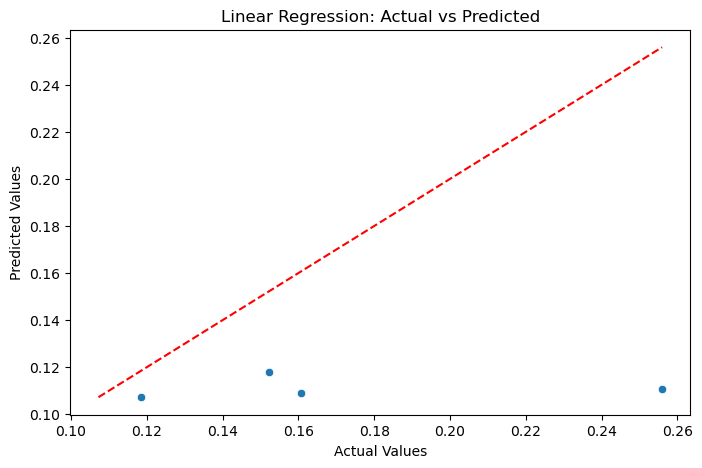

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.scatterplot(x=y_test_reg, y=y_pred_reg)

# Perfect prediction line
lims = [min(y_test_reg.min(), y_pred_reg.min()), max(y_test_reg.max(), y_pred_reg.max())]
plt.plot(lims, lims, 'r--')

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

In [12]:
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

df = pd.read_csv("articles.csv")
df = df.dropna(subset=["text"])
if "polarity" not in df.columns:
    from textblob import TextBlob
    df["polarity"] = df["text"].apply(lambda t: TextBlob(t).sentiment.polarity)
    
median = df["polarity"].median()
y = (df["polarity"] > median).astype(int)
X = df["text"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000)),
    ("clf", LogisticRegression(max_iter=1000)),
])
pipe.fit(X_train, y_train)

pred = pipe.predict(X_test)
print("Median polarity:", median)
print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion matrix (rows=true, cols=predicted):")
print(confusion_matrix(y_test, pred))

joblib.dump(pipe, "sentiment_pipeline.joblib")
print("Saved.")

Median polarity: 0.12962962962962962
Accuracy: 0.5
Confusion matrix (rows=true, cols=predicted):
[[2 0]
 [2 0]]
Saved.


In [13]:
import joblib

pipe = joblib.load("sentiment_pipeline.joblib")

text = "The new policy was widely praised and brought great improvements."
label = pipe.predict([text])[0]
print("Prediction:", "above median" if label == 1 else "below median")
print("Probabilities [below, above]:", pipe.predict_proba([text])[0])

Prediction: below median
Probabilities [below, above]: [0.51952249 0.48047751]


In [2]:
import joblib
import pandas as pd

reg_model = joblib.load("linear_model.pkl")

tfidf = reg_model[0]
model = reg_model[-1]

coef_df = pd.DataFrame({
    "feature": tfidf.get_feature_names_out(),
    "coef": model.coef_
})
coef_df["abs_coef"] = coef_df["coef"].abs()

print(coef_df.sort_values("abs_coef", ascending=False).head(10))

          feature      coef  abs_coef
2786   submodules -0.065220  0.065220
2785    submodule -0.065220  0.065220
2010       option -0.048600  0.048600
2881         test  0.048119  0.048119
486   calibration -0.037611  0.037611
337          auto -0.037611  0.037611
2401         repo -0.037480  0.037480
1873          mpu -0.035994  0.035994
1158     february -0.033760  0.033760
698      contexts -0.033760  0.033760


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

tree_model = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", max_features=20000)),
    ("clf", DecisionTreeClassifier(random_state=42)),
])
tree_model.fit(X_train_cls, y_train_cls)

y_pred_cls = tree_model.predict(X_test_cls)

print("Accuracy:", accuracy_score(y_test_cls, y_pred_cls))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_cls, y_pred_cls))
print("\nClassification Report:\n", classification_report(y_test_cls, y_pred_cls, zero_division=0))

Accuracy: 0.6

Confusion Matrix:
 [[2 1]
 [1 1]]

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       0.50      0.50      0.50         2

    accuracy                           0.60         5
   macro avg       0.58      0.58      0.58         5
weighted avg       0.60      0.60      0.60         5



In [ ]:
 Q3 Read the iris confusion matrix and name which two species the model confuses.
Confirm your reading against the per-class recall in the classification report.
     
The model confuses versicolor and virginica, because the only off-diagonal counts are between those two, and the report confirms it with setosa recall at 1.00 and lower recall for versicolor and virginica.

Q1 Report the $R^2$ of the plain `LinearRegression` and of the `Pipeline`. Explain why
standardisation leaves the score of an ordinary least-squares fit essentially unchanged, and name
a model family for which it would **not**
              
Standardisation leaves ordinary least squares unchanged because it only rescales each feature, and the fitted coefficients rescale to compensate, so the predictions and R² stay the same. It would matter for regularised models such as Ridge or Lasso, because their penalty depends on the size of the coefficients.